<a href="https://colab.research.google.com/github/maya300/Introduction_machine_learning/blob/main/Tutorial5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [8]:
!pwd

/content/gdrive/MyDrive/Machine_learning/Colab_Notebooks


# **Neural Network by Hand**

In this tutorial, you will code a little neural network from scratch.

We’ll use the network to solve the classic XOR problem. This is how the data look like:


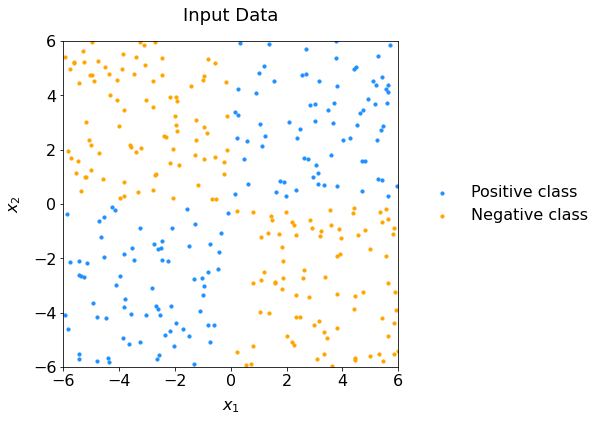



Fig. 62 Scatter plot of data representing the XOR configuration: it is not linearly separable.

# **Part I: Code Your Neural Network**

# **1.1 Get the Data**

# **Setup**

In [20]:
import numpy as np
import pandas as pd
import random
import math
np.random.seed(42)

import matplotlib.pyplot as plt
FONTSIZE = 16
params = {
         'figure.figsize' : (6,6),
         'axes.labelsize' : FONTSIZE,
         'axes.titlesize' : FONTSIZE+2,
         'legend.fontsize': FONTSIZE,
         'xtick.labelsize': FONTSIZE,
         'ytick.labelsize': FONTSIZE,
         'xtick.color'    : 'black',
         'ytick.color'    : 'black',
         'axes.facecolor' : 'white',
         'axes.edgecolor' : 'black',
         'axes.titlepad'  :  20,
         'axes.labelpad'  :  10}
plt.rcParams.update(params)

XNAME = 'x1'; XLABEL = r'$x_1$'
YNAME = 'x2'; YLABEL = r'$x_2$'
RANGE = (-6, 6); STEP = 0.1

def predict(output_node, boundary_value):
    output_node = output_node.reshape(-1, 1, 1)
    predictions = (output_node > boundary_value).astype(int)
    return predictions

def plot_cost_vs_iter(train_costs, test_costs, title="Cost evolution"):

    fig, ax = plt.subplots(figsize=(8, 6))
    iters = np.arange(1,len(train_costs)+1)
    ax.plot(iters, train_costs, color='red', lw=1, label='Training set')
    ax.plot(iters, test_costs, color='blue', lw=1, label='Testing set')
    ax.set_xlabel("Number of iterations"); ax.set_xlim(1, iters[-1])
    ax.set_ylabel("Cost")
    ax.legend(loc="upper right", frameon=False)
    ax.set_title(title)
    plt.show()

def get_decision_surface(weights, biases, boundary=0.5, range=RANGE, step=STEP):

    # Create a grid of points spanning the parameter space:
    x1v, x2v = np.meshgrid(np.arange(range[0], range[1]+step, step),
                           np.arange(range[0], range[1]+step, step)
    )

    # Stack it so that it is shaped like X_train: (m,2)
    X_grid = np.c_[x1v.ravel(), x2v.ravel()].reshape(-1,2)

    # Feedforward on all grid points and get binary predictions:
    output = feedforward(X_grid, weights, biases)[-1] # getting only output node
    Ypred_grid = predict(output, boundary)

    return (x1v, x2v, Ypred_grid.reshape(x1v.shape))


def plot_scatter(sig, bkg, ds=None,
                 xname=XNAME, xlabel=XLABEL,
                 yname=YNAME, ylabel=YLABEL,
                 range=RANGE, step=STEP, title="Scatter plot"):

    fig, ax = plt.subplots()

    # Decision surface
    if ds:
        (xx, yy, Z) = ds # unpack contour data
        cs = plt.contourf(xx, yy, Z, levels=[0,0.5,1], colors=['orange','dodgerblue'], alpha=0.3)

    # Scatter signal and background:
    ax.scatter(sig[xname], sig[yname], marker='o', s=10, c='dodgerblue', alpha=1, label='Positive class')
    ax.scatter(bkg[xname], bkg[yname], marker='o', s=10, c='orange',     alpha=1, label='Negative class')

    # Axes, legend and plot:
    ax.set_xlim(range); ax.set_xlabel(xlabel)
    ax.set_ylim(range); ax.set_ylabel(ylabel)

    ax.legend(bbox_to_anchor=(1.04, 0.5), loc="center left", frameon=False)
    ax.set_title(title)
    plt.show()

def print_every(iter_idx):
    if iter_idx <= 100:
        return iter_idx % 10 == 0
    elif iter_idx <= 1000:
        return iter_idx % 100 == 0
    else:
        return iter_idx % 1000 == 0

# **Split Signal vs Background**

In [10]:
file_train = "ml_tutorial_5_data_train.csv"
df_train = pd.read_csv(file_train)

In [11]:
# Train variables
XNAME = 'x1'; XLABEL = r'$x1$'
YNAME = 'x2'; YLABEL = r'$x2$'

inputs = [XNAME, YNAME]

# Split training data into signal and background
sig = df_train.loc[df_train['class'] == 1,  inputs]
bkg = df_train.loc[df_train['class'] == 0, inputs]

print(len(sig), len(bkg))

149 171


# **Dataframe to NumPy**

In [12]:
file_test = "ml_tutorial_5_data_test.csv"
df_test = pd.read_csv(file_test)

In [13]:
#Test data to numpy array
X_test = df_test[inputs].to_numpy()
y_test = df_test['class'].to_numpy()

#Train data to numpy array
X_train = df_train[inputs].to_numpy()
y_train = df_train['class'].to_numpy()

print(len(X_test), len(y_test), '\n')
print(len(X_train), len(y_train))

80 80 

320 320


# **1.2 Functions**

# **Weighted Sum**

In [14]:
def z(W, x, b):
  return W.T @ x + b

# **Activation Functions and Derivatives**

In [15]:
def tanh(z):
    return np.tanh(z)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)

def tanh_prime(z):
    return 1.0 - np.tanh(z)**2

# **Cross-entropy cost function**

In [16]:
def cross_entropy_cost(y_pred, y_true):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    m = y_true.shape[0]
    return -np.sum(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred)) / m

# **Derivative of the Loss**

In [17]:
def L_prime(y_pred, y_true):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return (y_pred - y_true) / (y_pred * (1 - y_pred))

# **1.3 Feedforward Propagation**

# **Implementing the Feedforward Function**

In [18]:
def feedforward(input_X, weights, biases):
    W1, W2, W3 = weights
    b1, b2, b3 = biases

    m  = len(input_X)
    a0 = input_X.reshape((m, -1, 1))

    # First layer
    z1 = z(W1, a0, b1)
    a1 = tanh(z1)

    # Second layer
    z2 = z(W2, a1, b2)
    a2 = tanh(z2)

    # Third layer
    z3 = z(W3, a2, b3)
    a3 = sigmoid(z3)

    nodes = [a0, z1, a1, z2, a2, z3, a3]
    return nodes

# **Predict**

- **`output_node`** is the last element of the list returned by `feedforward`: `a3`, the sigmoid output of the last layer. It has shape `(m, 1, 1)`.
- **`predict`** returns integer class labels (0 or 1) with shape `(m, 1, 1)`

# **1.4 Neural Network Training**

In [21]:
# Hyperparameters
alpha  = 0.05
n_iter = 5000

# Initialization
m = len(X_train)        # number of data samples
n = X_train.shape[1]    # number of input features
q = 3                   # number of nodes in first hidden layer
r = 2                   # number of nodes in second hidden layer

# WEIGHT MATRICES + BIASES (random numbers in [0, 1])
W1 = np.random.random((n, q))
W2 = np.random.random((q, r))
W3 = np.random.random((r, 1))
b1 = np.random.random((q, 1))
b2 = np.random.random((r, 1))
b3 = np.random.random((1, 1))

# OUTPUT LAYER
y_train = np.reshape(y_train, (-1, 1, 1))
y_test  = np.reshape(y_test , (-1, 1, 1))

# Storing cost values for train and test datasets
costs_train = []
costs_test  = []

debug = False
print("Starting the training\n")

for iter_idx in range(1, n_iter + 1):

    # FORWARD PROPAGATION
    # Feedforward on test data:
    nodes_test = feedforward(X_test, [W1, W2, W3], [b1, b2, b3])
    ypred_test = nodes_test[-1]

    # Feedforward on train data:
    a0, z1, a1, z2, a2, z3, a3 = feedforward(X_train, [W1, W2, W3], [b1, b2, b3])
    ypred_train = a3

    # Cost computation and storage
    cost_train = cross_entropy_cost(ypred_train, y_train)
    cost_test  = cross_entropy_cost(ypred_test,  y_test)
    costs_train.append(cost_train)
    costs_test.append(cost_test)

    # BACKWARD PROPAGATION
    # Errors delta (shapes: (m, nodes, 1)):
    delta_3 = sigmoid_prime(z3) * L_prime(a3, y_train)
    delta_2 = tanh_prime(z2) * (W3 @ delta_3)
    delta_1 = tanh_prime(z1) * (W2 @ delta_2)

    # Partial derivatives: (1/m) * sum_i  a_prev (outer) delta
    dCostdW3 = np.sum(a2 @ np.transpose(delta_3, (0, 2, 1)), axis=0) / m
    dCostdW2 = np.sum(a1 @ np.transpose(delta_2, (0, 2, 1)), axis=0) / m
    dCostdW1 = np.sum(a0 @ np.transpose(delta_1, (0, 2, 1)), axis=0) / m
    dCostdb3 = np.sum(delta_3, axis=0) / m
    dCostdb2 = np.sum(delta_2, axis=0) / m
    dCostdb1 = np.sum(delta_1, axis=0) / m

    # Print selected iterations
    if print_every(iter_idx):
        print(
            f"Iteration {iter_idx:>4}\t"
            f"Train cost: {cost_train:.5f}\t"
            f"Test cost: {cost_test:.5f}\t"
            f"Diff: {cost_test - cost_train:.2e}"
        )

    if debug and iter_idx < 3:
        print(
            f"Nodes: a0={a0.shape}, a1={a1.shape}, a2={a2.shape}, a3={a3.shape} | "
            f"Weights: W1={W1.shape}, W2={W2.shape}, W3={W3.shape} | "
            f"Gradients: dW1={dCostdW1.shape}, dW2={dCostdW2.shape}, dW3={dCostdW3.shape}"
        )

    # Update of weights and biases
    W3 = W3 - alpha * dCostdW3
    W2 = W2 - alpha * dCostdW2
    W1 = W1 - alpha * dCostdW1
    b3 = b3 - alpha * dCostdb3
    b2 = b2 - alpha * dCostdb2
    b1 = b1 - alpha * dCostdb1

print(f'\nEnd of gradient descent after {iter_idx} iterations')

Starting the training

Iteration   10	Train cost: 0.77835	Test cost: 0.76665	Diff: -1.17e-02
Iteration   20	Train cost: 0.74398	Test cost: 0.73543	Diff: -8.55e-03
Iteration   30	Train cost: 0.72012	Test cost: 0.71469	Diff: -5.43e-03
Iteration   40	Train cost: 0.70343	Test cost: 0.70107	Diff: -2.36e-03
Iteration   50	Train cost: 0.69152	Test cost: 0.69213	Diff: 6.12e-04
Iteration   60	Train cost: 0.68276	Test cost: 0.68620	Diff: 3.44e-03
Iteration   70	Train cost: 0.67602	Test cost: 0.68212	Diff: 6.11e-03
Iteration   80	Train cost: 0.67054	Test cost: 0.67913	Diff: 8.59e-03
Iteration   90	Train cost: 0.66581	Test cost: 0.67671	Diff: 1.09e-02
Iteration  100	Train cost: 0.66146	Test cost: 0.67451	Diff: 1.30e-02
Iteration  200	Train cost: 0.60868	Test cost: 0.63840	Diff: 2.97e-02
Iteration  300	Train cost: 0.54441	Test cost: 0.58199	Diff: 3.76e-02
Iteration  400	Train cost: 0.49371	Test cost: 0.53647	Diff: 4.28e-02
Iteration  500	Train cost: 0.45881	Test cost: 0.50575	Diff: 4.69e-02
Iterati

# **1.5 Plots**

# **Cost evolution**

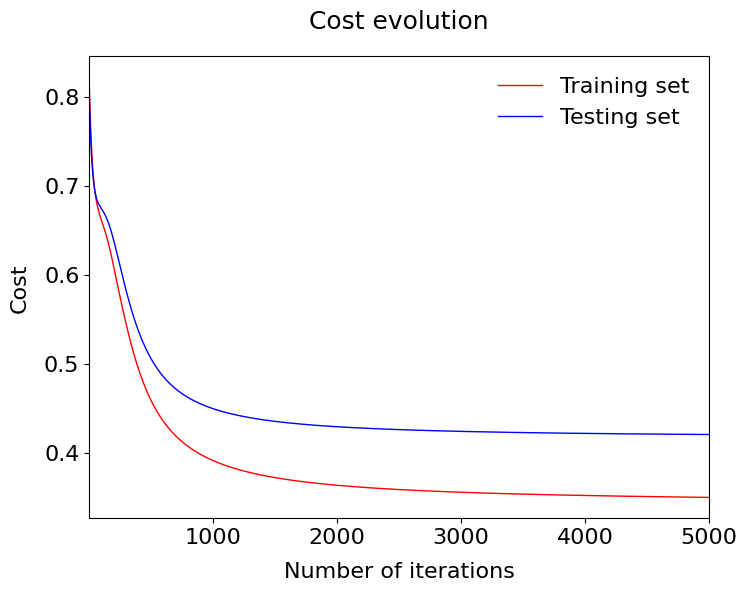

In [22]:
plot_cost_vs_iter(costs_train, costs_test)

# **Scatter Plot**

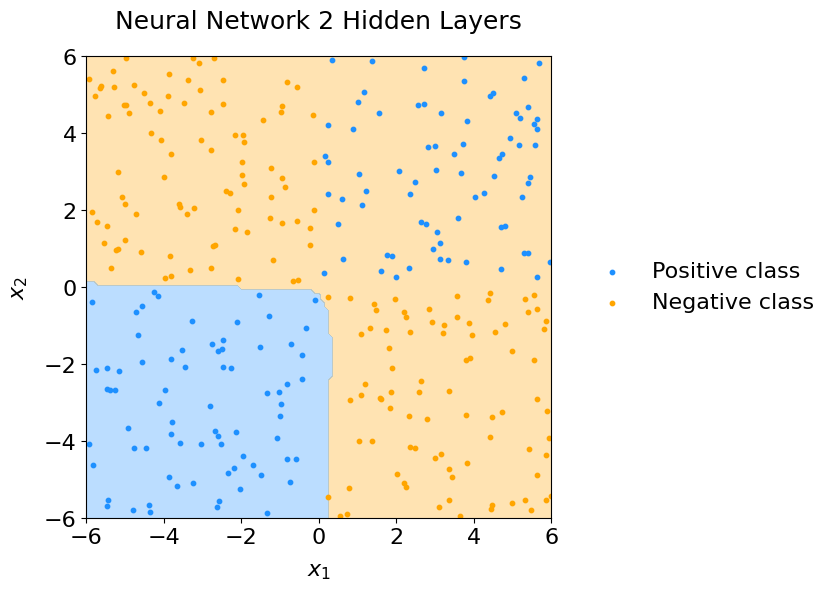

Test accuracy: 0.7


In [23]:
ds = get_decision_surface([W1, W2, W3], [b1, b2, b3])
plot_scatter(sig, bkg, ds=ds, title="Neural Network 2 Hidden Layers")

# Accuracy on the test set
y_hat = predict(feedforward(X_test, [W1, W2, W3], [b1, b2, b3])[-1], 0.5)
print("Test accuracy:", np.mean(y_hat == y_test))